<a href="https://colab.research.google.com/github/Anushyaaaa/dsa_lab/blob/main/Lab6_dsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MediQueue: Performance Comparison of Plain BST and AVL Tree

Objective: To implement a plain Binary Search Tree (BST) and a self-balancing AVL Tree for storing patient records, and compare their insertion time, tree height, search cost, and deletion performance under different workloads.It implements insertion, searching, deletion, traversal, height calculation, and comparison counting.

In [ ]:
class BSTNode:
    def __init__(self, key, name):
        self.key = key
        self.name = name
        self.left = None
        self.right = None


class BST:
    def __init__(self):
        self.root = None
        self.comparisons = 0

    def insert(self, key, name):
        new_node = BSTNode(key, name)

        if self.root is None:
            self.root = new_node
            return

        current = self.root

        while True:
            self.comparisons += 1

            if key == current.key:
                current.name = name
                return
            elif key < current.key:
                if current.left is None:
                    current.left = new_node
                    return
                current = current.left
            else:
                if current.right is None:
                    current.right = new_node
                    return
                current = current.right

    def search(self, key):
        current = self.root

        while current is not None:
            self.comparisons += 1

            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def delete(self, key):
        parent = None
        current = self.root

        # Find the node
        while current is not None:
            self.comparisons += 1

            if key == current.key:
                break

            parent = current
            if key < current.key:
                current = current.left
            else:
                current = current.right

        if current is None:
            return False

        # If there are two children, replace with inorder successor
        if current.left is not None and current.right is not None:
            successor_parent = current
            successor = current.right

            while successor.left is not None:
                successor_parent = successor
                successor = successor.left

            current.key = successor.key
            current.name = successor.name

            parent = successor_parent
            current = successor

        # Now the node has at most one child
        child = current.left if current.left is not None else current.right

        if parent is None:
            self.root = child
        elif parent.left is current:
            parent.left = child
        else:
            parent.right = child

        return True

    def inorder_traversal(self):
        result = []
        stack = []
        current = self.root

        # Iterative traversal avoids recursion problems
        while current is not None or stack:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append((current.key, current.name))
            current = current.right

        return result

    def height(self):
        if self.root is None:
            return 0

        max_height = 0
        stack = [(self.root, 1)]

        while stack:
            node, level = stack.pop()
            max_height = max(max_height, level)

            if node.left:
                stack.append((node.left, level + 1))
            if node.right:
                stack.append((node.right, level + 1))

        return max_height

    def is_bst(self):
        stack = [(self.root, float("-inf"), float("inf"))]

        while stack:
            node, low, high = stack.pop()

            if node is None:
                continue

            if not low < node.key < high:
                return False

            stack.append((node.left, low, node.key))
            stack.append((node.right, node.key, high))

        return True

This includes all four rotation cases, deletion rebalancing, and tree validation.

In [ ]:
class AVLNode:
    def __init__(self, key, name):
        self.key = key
        self.name = name
        self.left = None
        self.right = None
        self.height = 1


class AVLTree:
    def __init__(self):
        self.root = None
        self.comparisons = 0
        self.rotations = 0

    def _height(self, node):
        return node.height if node else 0

    def _update(self, node):
        node.height = 1 + max(
            self._height(node.left),
            self._height(node.right)
        )

    def _balance(self, node):
        if node is None:
            return 0
        return self._height(node.left) - self._height(node.right)

    def _rotate_right(self, y):
        x = y.left
        middle = x.right

        x.right = y
        y.left = middle

        self._update(y)
        self._update(x)
        self.rotations += 1
        return x

    def _rotate_left(self, x):
        y = x.right
        middle = y.left

        y.left = x
        x.right = middle

        self._update(x)
        self._update(y)
        self.rotations += 1
        return y

    def _rebalance(self, node):
        if node is None:
            return node

        self._update(node)
        balance = self._balance(node)

        # Left-heavy
        if balance > 1:
            if self._balance(node.left) < 0:
                node.left = self._rotate_left(node.left)  # LR
            return self._rotate_right(node)               # LL

        # Right-heavy
        if balance < -1:
            if self._balance(node.right) > 0:
                node.right = self._rotate_right(node.right)  # RL
            return self._rotate_left(node)                   # RR

        return node

    def insert(self, key, name):
        self.root = self._insert(self.root, key, name)

    def _insert(self, node, key, name):
        if node is None:
            return AVLNode(key, name)

        self.comparisons += 1

        if key == node.key:
            node.name = name
            return node
        elif key < node.key:
            node.left = self._insert(node.left, key, name)
        else:
            node.right = self._insert(node.right, key, name)

        return self._rebalance(node)

    def search(self, key):
        current = self.root

        while current is not None:
            self.comparisons += 1

            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def delete(self, key):
        self.root, deleted = self._delete(self.root, key)
        return deleted

    def _delete(self, node, key):
        if node is None:
            return None, False

        self.comparisons += 1
        deleted = False

        if key < node.key:
            node.left, deleted = self._delete(node.left, key)
        elif key > node.key:
            node.right, deleted = self._delete(node.right, key)
        else:
            deleted = True

            if node.left is None:
                return node.right, True
            elif node.right is None:
                return node.left, True
            else:
                successor = node.right
                while successor.left is not None:
                    successor = successor.left

                node.key = successor.key
                node.name = successor.name
                node.right, _ = self._delete(node.right, successor.key)

        if node is not None:
            node = self._rebalance(node)

        return node, deleted

    def height(self):
        return self._height(self.root)

    def inorder_traversal(self):
        result = []
        stack = []
        current = self.root

        while current is not None or stack:
            while current is not None:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append((current.key, current.name))
            current = current.right

        return result

    def is_bst(self):
        stack = [(self.root, float("-inf"), float("inf"))]

        while stack:
            node, low, high = stack.pop()

            if node is None:
                continue

            if not low < node.key < high:
                return False

            stack.append((node.left, low, node.key))
            stack.append((node.right, node.key, high))

        return True

    def is_balanced(self):
        stack = [self.root]

        while stack:
            node = stack.pop()

            if node is None:
                continue

            if abs(self._balance(node)) > 1:
                return False

            expected_height = 1 + max(
                self._height(node.left),
                self._height(node.right)
            )

            if node.height != expected_height:
                return False

            stack.append(node.left)
            stack.append(node.right)

        return True

The fixed seed makes your experiments reproducible.

In [ ]:
import random
import math
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SIZES = [1000, 5000, 10000]
SEED = 42

def generate_workloads(n, seed=SEED):
    rng = random.Random(seed)

    sequential = list(range(1, n + 1))

    random_data = sequential.copy()
    rng.shuffle(random_data)

    nearly_sorted = sequential.copy()
    number_of_positions = max(1, round(n * 0.05))
    positions = rng.sample(range(n), number_of_positions)

    shuffled_values = [nearly_sorted[i] for i in positions]
    rng.shuffle(shuffled_values)

    for i, value in zip(positions, shuffled_values):
        nearly_sorted[i] = value

    return {
        "Sequential": sequential,
        "Random": random_data,
        "Nearly sorted": nearly_sorted
    }

# Preview the datasets
for dataset_name, data in generate_workloads(20).items():
    print(dataset_name, ":", data)

Sequential : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Random : [20, 6, 15, 5, 10, 14, 16, 19, 7, 13, 18, 11, 2, 12, 3, 17, 8, 9, 1, 4]
Nearly sorted : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


This cell measures insertion time, height, average successful-search comparisons, rotations, and height after deleting 20% of the keys.

In [ ]:
def run_experiments():
    rows = []

    for n in SIZES:
        workloads = generate_workloads(n, SEED + n)

        # Use identical search and deletion keys for both trees
        rng = random.Random(SEED + 100 + n)
        search_keys = [rng.randint(1, n) for _ in range(1000)]

        deletion_keys = rng.sample(
            range(1, n + 1), round(n * 0.20)
        )

        for dataset_name, data in workloads.items():
            for tree_name, TreeClass in [
                ("Plain BST", BST),
                ("AVL", AVLTree)
            ]:
                tree = TreeClass()

                start = time.perf_counter()
                for key in data:
                    tree.insert(key, f"Patient_{key}")
                insertion_ms = (time.perf_counter() - start) * 1000

                height_before = tree.height()
                insertion_rotations = getattr(tree, "rotations", 0)

                # Check correctness after insertion
                assert tree.is_bst(), (
                    f"BST property failed: {tree_name}, {dataset_name}, {n}"
                )

                if tree_name == "AVL":
                    assert tree.is_balanced(), (
                        f"AVL balance failed: {dataset_name}, {n}"
                    )

                # Measure comparisons only during successful searches
                tree.comparisons = 0

                for key in search_keys:
                    assert tree.search(key) is not None

                average_search_comparisons = tree.comparisons / len(search_keys)

                # Delete the same 20% of keys from each tree
                tree.rotations = 0 if tree_name == "AVL" else getattr(
                    tree, "rotations", 0
                )

                rotations_before_delete = getattr(tree, "rotations", 0)

                for key in deletion_keys:
                    assert tree.delete(key)

                deletion_rotations = (
                    getattr(tree, "rotations", 0) - rotations_before_delete
                    if tree_name == "AVL" else 0
                )

                height_after_delete = tree.height()

                assert tree.is_bst()
                if tree_name == "AVL":
                    assert tree.is_balanced()

                rows.append({
                    "N": n,
                    "Dataset": dataset_name,
                    "Tree": tree_name,
                    "Insertion_Time_ms": round(insertion_ms, 3),
                    "Height_After_Insert": height_before,
                    "Theoretical_Min_Height_floor_log2N": math.floor(
                        math.log2(n)
                    ),
                    "Average_Search_Comparisons": round(
                        average_search_comparisons, 3
                    ),
                    "Insertion_Rotations": insertion_rotations,
                    "Deletion_Rotations": deletion_rotations,
                    "Height_After_Deleting_20_Percent": height_after_delete
                })

                print(
                    f"Finished: N={n}, {dataset_name}, {tree_name}"
                )

    return pd.DataFrame(rows)


results = run_experiments()

print("\nCOMPARISON RESULTS")
display(results)

Path("results/graphs").mkdir(parents=True, exist_ok=True)
results.to_csv("comparison_results.csv", index=False)

print("Saved comparison_results.csv")

Finished: N=1000, Sequential, Plain BST
Finished: N=1000, Sequential, AVL
Finished: N=1000, Random, Plain BST
Finished: N=1000, Random, AVL
Finished: N=1000, Nearly sorted, Plain BST
Finished: N=1000, Nearly sorted, AVL
Finished: N=5000, Sequential, Plain BST
Finished: N=5000, Sequential, AVL
Finished: N=5000, Random, Plain BST
Finished: N=5000, Random, AVL
Finished: N=5000, Nearly sorted, Plain BST
Finished: N=5000, Nearly sorted, AVL
Finished: N=10000, Sequential, Plain BST
Finished: N=10000, Sequential, AVL
Finished: N=10000, Random, Plain BST
Finished: N=10000, Random, AVL
Finished: N=10000, Nearly sorted, Plain BST
Finished: N=10000, Nearly sorted, AVL

COMPARISON RESULTS


,N,Dataset,Tree,Insertion_Time_ms,Height_After_Insert,Theoretical_Min_Height_floor_log2N,Average_Search_Comparisons,Insertion_Rotations,Deletion_Rotations,Height_After_Deleting_20_Percent
0,1000,Sequential,Plain BST,485.382,1000,9,505.382,0,0,800
1,1000,Sequential,AVL,23.332,10,9,8.984,990,11,10
2,1000,Random,Plain BST,17.459,23,9,12.392,0,0,21
3,1000,Random,AVL,39.700,12,9,9.189,700,79,12
4,1000,Nearly sorted,Plain BST,12.162,204,9,50.729,0,0,163
5,1000,Nearly sorted,AVL,14.208,11,9,9.162,1135,49,11
6,5000,Sequential,Plain BST,1955.118,5000,12,2549.006,0,0,4000
7,5000,Sequential,AVL,43.743,13,12,11.422,4987,47,13
8,5000,Random,Plain BST,10.813,29,12,14.711,0,0,27
9,5000,Random,AVL,44.998,14,12,11.495,3552,346,14


Saved comparison_results.csv


It generates four graphs using your actual measurements.

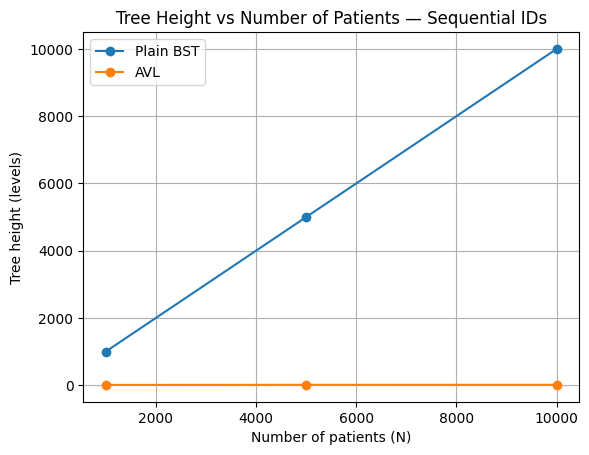

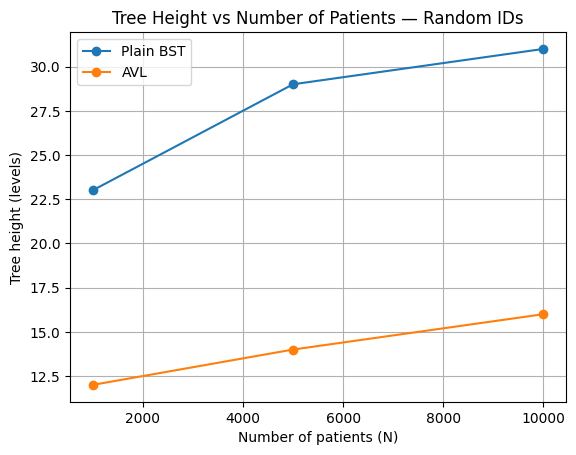

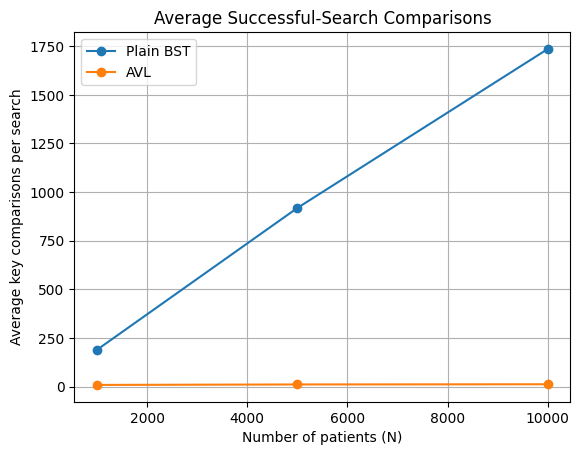

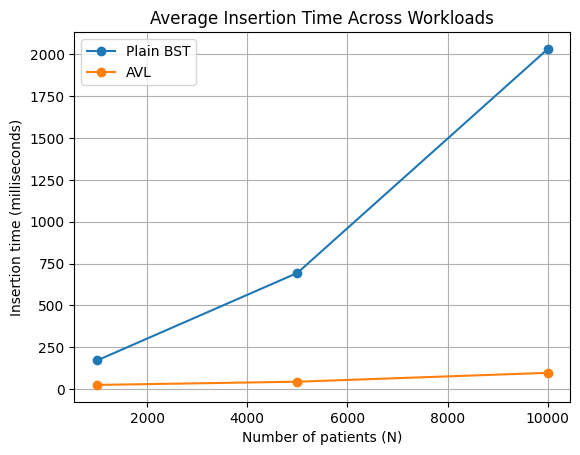

All four graphs saved in results/graphs/


In [ ]:
# Graph 1: Height on sequential dataset
seq = results[results["Dataset"] == "Sequential"]

for tree_name in ["Plain BST", "AVL"]:
    subset = seq[seq["Tree"] == tree_name].sort_values("N")
    plt.plot(
        subset["N"],
        subset["Height_After_Insert"],
        marker="o",
        label=tree_name
    )

plt.title("Tree Height vs Number of Patients — Sequential IDs")
plt.xlabel("Number of patients (N)")
plt.ylabel("Tree height (levels)")
plt.legend()
plt.grid(True)
plt.savefig("results/graphs/sequential_height.png", bbox_inches="tight")
plt.show()


# Graph 2: Height on random dataset
random_results = results[results["Dataset"] == "Random"]

for tree_name in ["Plain BST", "AVL"]:
    subset = random_results[random_results["Tree"] == tree_name].sort_values("N")
    plt.plot(
        subset["N"],
        subset["Height_After_Insert"],
        marker="o",
        label=tree_name
    )

plt.title("Tree Height vs Number of Patients — Random IDs")
plt.xlabel("Number of patients (N)")
plt.ylabel("Tree height (levels)")
plt.legend()
plt.grid(True)
plt.savefig("results/graphs/random_height.png", bbox_inches="tight")
plt.show()


# Graph 3: Average successful-search comparisons
for tree_name in ["Plain BST", "AVL"]:
    subset = results[results["Tree"] == tree_name]
    grouped = subset.groupby("N")["Average_Search_Comparisons"].mean()
    plt.plot(grouped.index, grouped.values, marker="o", label=tree_name)

plt.title("Average Successful-Search Comparisons")
plt.xlabel("Number of patients (N)")
plt.ylabel("Average key comparisons per search")
plt.legend()
plt.grid(True)
plt.savefig("results/graphs/search_comparisons.png", bbox_inches="tight")
plt.show()


# Graph 4: Insertion time
for tree_name in ["Plain BST", "AVL"]:
    subset = results[results["Tree"] == tree_name]
    grouped = subset.groupby("N")["Insertion_Time_ms"].mean()
    plt.plot(grouped.index, grouped.values, marker="o", label=tree_name)

plt.title("Average Insertion Time Across Workloads")
plt.xlabel("Number of patients (N)")
plt.ylabel("Insertion time (milliseconds)")
plt.legend()
plt.grid(True)
plt.savefig("results/graphs/insertion_time.png", bbox_inches="tight")
plt.show()

print("All four graphs saved in results/graphs/")

Demonstrate the sample sequence

In [ ]:
sample_ids = [10, 20, 30, 40, 50, 25]

plain = BST()
avl = AVLTree()

for key in sample_ids:
    plain.insert(key, f"Patient_{key}")
    avl.insert(key, f"Patient_{key}")

print("PLAIN BST")
print("Root:", plain.root.key)
print("Height:", plain.height())
print("In-order traversal:", [key for key, name in plain.inorder_traversal()])

print("\nAVL TREE")
print("Root:", avl.root.key)
print("Height:", avl.height())
print("In-order traversal:", [key for key, name in avl.inorder_traversal()])
print("Rotations:", avl.rotations)
print("BST property:", avl.is_bst())
print("Balanced:", avl.is_balanced())

assert plain.root.key == 10
assert plain.height() == 5
assert avl.root.key == 30
assert avl.height() == 3
assert avl.rotations == 4
assert avl.is_bst()
assert avl.is_balanced()

PLAIN BST
Root: 10
Height: 5
In-order traversal: [10, 20, 25, 30, 40, 50]

AVL TREE
Root: 30
Height: 3
In-order traversal: [10, 20, 25, 30, 40, 50]
Rotations: 4
BST property: True
Balanced: True


self-learning component — Treap

In [ ]:
class TreapNode:
    def __init__(self, key, name, priority):
        self.key = key
        self.name = name
        self.priority = priority
        self.left = None
        self.right = None


class Treap:
    def __init__(self, seed=42):
        self.root = None
        self.rng = random.Random(seed)

    def _rotate_right(self, node):
        child = node.left
        node.left = child.right
        child.right = node
        return child

    def _rotate_left(self, node):
        child = node.right
        node.right = child.left
        child.left = node
        return child

    def insert(self, key, name):
        self.root = self._insert(self.root, key, name)

    def _insert(self, node, key, name):
        if node is None:
            return TreapNode(key, name, self.rng.random())

        if key == node.key:
            node.name = name
        elif key < node.key:
            node.left = self._insert(node.left, key, name)

            if node.left.priority < node.priority:
                node = self._rotate_right(node)
        else:
            node.right = self._insert(node.right, key, name)

            if node.right.priority < node.priority:
                node = self._rotate_left(node)

        return node

    def search(self, key):
        node = self.root

        while node:
            if key == node.key:
                return node.name
            node = node.left if key < node.key else node.right

        return None

    def height(self):
        if self.root is None:
            return 0

        maximum = 0
        stack = [(self.root, 1)]

        while stack:
            node, level = stack.pop()
            maximum = max(maximum, level)

            if node.left:
                stack.append((node.left, level + 1))
            if node.right:
                stack.append((node.right, level + 1))

        return maximum

    def inorder_traversal(self):
        result = []
        stack = []
        node = self.root

        while node or stack:
            while node:
                stack.append(node)
                node = node.left

            node = stack.pop()
            result.append((node.key, node.name))
            node = node.right

        return result

    def is_bst(self):
        stack = [(self.root, float("-inf"), float("inf"))]

        while stack:
            node, low, high = stack.pop()

            if node is None:
                continue

            if not low < node.key < high:
                return False

            stack.append((node.left, low, node.key))
            stack.append((node.right, node.key, high))

        return True

A Treap usually achieves expected logarithmic height when priorities are random, but it does not guarantee logarithmic height for every possible priority assignment. This is an important difference from AVL.

,N,Tree,Height,Insertion_Time_ms
0,1000,Plain BST,1000,59.393
1,1000,AVL,10,7.399
2,1000,Treap,22,1.780
3,5000,Plain BST,5000,3310.251
4,5000,AVL,13,258.611
5,5000,Treap,26,99.297
6,10000,Plain BST,10000,6875.919
7,10000,AVL,14,93.292
8,10000,Treap,34,19.757


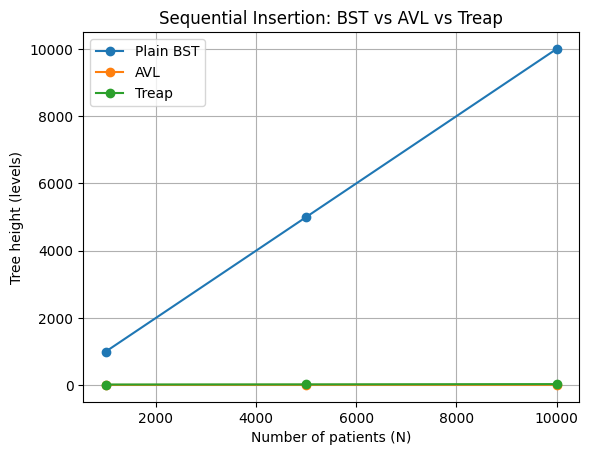

In [ ]:
treap_rows = []

for n in SIZES:
    data = list(range(1, n + 1))

    for name, TreeClass in [
        ("Plain BST", BST),
        ("AVL", AVLTree),
        ("Treap", Treap)
    ]:
        tree = TreeClass() if name != "Treap" else Treap(seed=SEED + n)

        start = time.perf_counter()
        for key in data:
            tree.insert(key, f"Patient_{key}")
        elapsed_ms = (time.perf_counter() - start) * 1000

        assert tree.is_bst()

        if name == "AVL":
            assert tree.is_balanced()

        treap_rows.append({
            "N": n,
            "Tree": name,
            "Height": tree.height(),
            "Insertion_Time_ms": round(elapsed_ms, 3)
        })

treap_results = pd.DataFrame(treap_rows)
display(treap_results)
treap_results.to_csv("treap_sequential_results.csv", index=False)

plt.figure()
for name in ["Plain BST", "AVL", "Treap"]:
    subset = treap_results[treap_results["Tree"] == name]
    plt.plot(subset["N"], subset["Height"], marker="o", label=name)

plt.title("Sequential Insertion: BST vs AVL vs Treap")
plt.xlabel("Number of patients (N)")
plt.ylabel("Tree height (levels)")
plt.legend()
plt.grid(True)
plt.savefig("results/graphs/treap_comparison.png", bbox_inches="tight")
plt.show()

In [ ]:
# Find the worst plain-BST case in your actual results
bst_results = results[results["Tree"] == "Plain BST"]
worst = bst_results.sort_values("Height_After_Insert", ascending=False).iloc[0]

random_bst = results[
    (results["Dataset"] == "Random") & (results["Tree"] == "Plain BST")
].sort_values("N")

random_avl = results[
    (results["Dataset"] == "Random") & (results["Tree"] == "AVL")
].sort_values("N")

random_comparison = random_bst.merge(
    random_avl,
    on="N",
    suffixes=("_BST", "_AVL")
)

random_summary = "\n".join(
    f"- N={int(r['N'])}: BST height {int(r['Height_After_Insert_BST'])}, "
    f"AVL height {int(r['Height_After_Insert_AVL'])}; "
    f"BST average search comparisons "
    f"{r['Average_Search_Comparisons_BST']:.3f}, "
    f"AVL average search comparisons "
    f"{r['Average_Search_Comparisons_AVL']:.3f}."
    for _, r in random_comparison.iterrows()
)

analysis_text = f"""# Part E — Analysis of MediQueue BST and AVL Experiments

## 1. Worst case for the plain BST

The largest measured plain-BST height in these experiments occurred for the
**{worst['Dataset']}** dataset with N={int(worst['N'])}. Its measured height
was {int(worst['Height_After_Insert'])} levels, and its average successful-search
cost was {worst['Average_Search_Comparisons']:.3f} key comparisons. Insertion
order affects a plain BST strongly: ascending IDs can create a chain-like tree.

## 2. Extra work required by AVL

AVL stores a height value at each node and updates it after structural changes.
It checks balance factors and may perform rotations. For example, for the
sequential dataset with N=10,000, the AVL tree performed
{int(results[(results['N'] == 10000) & (results['Dataset'] == 'Sequential') &
             (results['Tree'] == 'AVL')]['Insertion_Rotations'].iloc[0])}
primitive rotations during insertion. These operations add bookkeeping and
runtime overhead, and each node needs an additional height field. In exchange,
AVL maintains logarithmic height, preventing the linear-height degeneration
seen in an unbalanced BST.

## 3. Random dataset comparison

{random_summary}

On random input, a plain BST may already be reasonably balanced by chance.
Compare the measured heights, search costs and insertion times above rather
than assuming AVL is always faster. AVL's main benefit is its balance guarantee,
especially when input order is unfavorable.

## 4. Recommendation

I recommend AVL for MediQueue because patient IDs arrive in ascending order.
The measured sequential workload shows the effect of insertion order on the
plain BST, while AVL rotations keep the tree balanced. This helps keep search,
insertion and deletion operations logarithmic in the worst case. AVL does
perform extra height updates and rotations, so the final decision should
consider the measured timings as well as the predictable search performance.

## Measurement notes

Height is measured in levels: an empty tree has height 0 and a leaf has height 1.
The theoretical reference requested in the assignment is floor(log2(N)).
Average search comparisons are measured across 1,000 successful searches.
All reported numbers are from this notebook's executed benchmark.
"""

Path("analysis.md").write_text(analysis_text, encoding="utf-8")
print(analysis_text)

# Part E — Analysis of MediQueue BST and AVL Experiments

## 1. Worst case for the plain BST

The largest measured plain-BST height in these experiments occurred for the
**Sequential** dataset with N=10000. Its measured height
was 10000 levels, and its average successful-search
cost was 5057.190 key comparisons. Insertion
order affects a plain BST strongly: ascending IDs can create a chain-like tree.

## 2. Extra work required by AVL

AVL stores a height value at each node and updates it after structural changes.
It checks balance factors and may perform rotations. For example, for the
sequential dataset with N=10,000, the AVL tree performed
9986
primitive rotations during insertion. These operations add bookkeeping and
runtime overhead, and each node needs an additional height field. In exchange,
AVL maintains logarithmic height, preventing the linear-height degeneration
seen in an unbalanced BST.

## 3. Random dataset comparison

- N=1000: BST height 23, AVL height 12; BST average se

In [ ]:
# Basic correctness tests
def run_tests():
    # BST insertion, search, deletion and traversal
    b = BST()
    for key in [20, 10, 30, 5, 15, 25, 35]:
        b.insert(key, f"Patient_{key}")

    assert b.search(15) == "Patient_15"
    assert b.search(999) is None
    assert b.is_bst()

    # Leaf deletion, one-child deletion and two-child deletion
    assert b.delete(5)       # leaf
    assert b.delete(10)      # one child (15 remains)
    assert b.delete(30)      # two children (25 and 35)
    assert b.is_bst()
    assert [k for k, _ in b.inorder_traversal()] == [15, 20, 25, 35]

    # All four AVL rotation patterns
    for sequence in ([30, 20, 10], [10, 20, 30],
                     [30, 10, 20], [10, 30, 20]):
        a = AVLTree()
        for key in sequence:
            a.insert(key, f"Patient_{key}")
        assert a.root.key == 20
        assert a.is_bst()
        assert a.is_balanced()

    # AVL deletion must preserve balance
    a = AVLTree()
    for key in range(1, 101):
        a.insert(key, f"Patient_{key}")
    for key in range(1, 51):
        a.delete(key)
        assert a.is_bst()
        assert a.is_balanced()

    # Treap ordering and search
    t = Treap(seed=42)
    for key in [20, 10, 30, 5, 15]:
        t.insert(key, f"Patient_{key}")
    assert t.is_bst()
    assert t.search(15) == "Patient_15"
    assert [k for k, _ in t.inorder_traversal()] == [5, 10, 15, 20, 30]

    # Large sequential BST insertion must not recurse
    large = BST()
    for key in range(1, 10001):
        large.insert(key, f"Patient_{key}")
    assert large.height() == 10000
    assert large.is_bst()

    print("All basic correctness tests passed!")


run_tests()


# Build the self-learning note from measured Treap results
treap_summary = "\n".join(
    f"- N={int(r['N'])}: {r['Tree']} height={int(r['Height'])}, "
    f"insertion time={r['Insertion_Time_ms']:.3f} ms."
    for _, r in treap_results.iterrows()
)

self_learning_text = f"""# Self-Learning Note: Treap

## Balancing idea

A Treap is a binary search tree ordered by key and also a heap ordered by
random priorities. When an inserted node violates the heap-priority order,
rotations restore the priority property while preserving BST key ordering.

## Height bound and comparison with AVL

With independently random priorities, a Treap has expected logarithmic height.
However, a Treap can still have linear height in the worst case. AVL trees
instead enforce a strict balance-factor rule at every node, guaranteeing
logarithmic worst-case height. Treap priorities are randomized; AVL balancing
uses node heights and deterministic rotation rules.

## Sequential insertion experiment

These measurements were generated by this notebook:

{treap_summary}

The Treap experiment uses a fixed random seed for reproducibility. Its observed
height is one sample, not a guarantee for every possible priority assignment.
Compare it with the AVL and plain BST heights in the generated graph.

## Conclusion

Sequential keys create a chain in the plain BST. AVL rotations guarantee
balance, while Treap priorities usually reduce the tendency to form a chain.
For a system that needs a worst-case height guarantee, AVL provides the more
predictable bound.

## References to consult and cite after reading

- CP-Algorithms, “Treap”: https://cp-algorithms.com/data_structures/treap.html
- Open Data Structures, “Binary Search Trees”: https://opendatastructures.org/

Read the relevant sections and ensure the references match the explanations
before submitting the note.
"""

Path("self_learning.md").write_text(self_learning_text, encoding="utf-8")
print("Created self_learning.md")

All basic correctness tests passed!
Created self_learning.md


In [ ]:
import zipfile
from IPython.display import display

# Export previously executed notebook code cells as a Python source file.
# Keep the .ipynb notebook too: use Colab's File > Download > Download .ipynb.
try:
    notebook_cells = get_ipython().user_ns.get("In", [])
    previous_cells = notebook_cells[1:-1]

    source_text = (
        "# MediQueue BST vs AVL Lab\n"
        "# Export of executed Colab code cells.\n"
        "from IPython.display import display\n\n"
    )

    source_text += "\n\n".join(
        cell for cell in previous_cells if isinstance(cell, str) and cell.strip()
    )

    Path("mediQueue_colab_source.py").write_text(
        source_text, encoding="utf-8"
    )
    print("Created mediQueue_colab_source.py")
except Exception as error:
    print("Could not automatically export source:", error)

# Include only files that actually exist
files_to_package = [
    "mediQueue_colab_source.py",
    "comparison_results.csv",
    "treap_sequential_results.csv",
    "analysis.md",
    "self_learning.md"
]

for path in Path("results/graphs").glob("*.png"):
    files_to_package.append(str(path))

with zipfile.ZipFile("MediQueue_BST_AVL_Submission.zip", "w",
                     zipfile.ZIP_DEFLATED) as archive:
    for filename in files_to_package:
        if Path(filename).exists():
            archive.write(filename)

print("\nZIP created. Contents:")
with zipfile.ZipFile("MediQueue_BST_AVL_Submission.zip", "r") as archive:
    for filename in archive.namelist():
        print("-", filename)

print("\nDownload your ZIP:")
from google.colab import files
files.download("MediQueue_BST_AVL_Submission.zip")

Created mediQueue_colab_source.py

ZIP created. Contents:
- mediQueue_colab_source.py
- comparison_results.csv
- treap_sequential_results.csv
- analysis.md
- self_learning.md
- results/graphs/insertion_time.png
- results/graphs/random_height.png
- results/graphs/treap_comparison.png
- results/graphs/sequential_height.png
- results/graphs/search_comparisons.png

Download your ZIP:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

1\. Worst-case dataset for plain BST: The sequential dataset produced the worst case for the plain BST. For \\(N=10{,}000\\), its height was 10,000 and its average search cost was 5,057.190 comparisons. This happened because inserting elements in sorted order created a highly unbalanced tree.

2\. Extra work in AVL tree: For the sequential dataset with \\(N=10{,}000\\), the AVL tree performed 9,986 insertion rotations and 61 deletion rotations. It maintained a height of just 14 after insertion. The AVL tree also requires height updates and extra memory to store the height of each node, but these costs help maintain balance.

3\. AVL vs. BST on random dataset: For \\(N=10{,}000\\), the AVL tree had a height of 16 and an average search cost of 12.486 comparisons, while the plain BST had a height of 31 and an average search cost of 16.565 comparisons. Therefore, the AVL tree provided better search performance, although it took longer to insert the elements in this experiment: 96.547 ms compared with 24.885 ms for the plain BST.

4\. Recommendation for MediQueue: I recommend the AVL tree for MediQueue because it maintains a balanced structure and provides consistently efficient searches, even when patient records are inserted in sorted order. Although it requires additional rotations, height bookkeeping, memory, and insertion time, these costs are justified by its predictable search performance and avoidance of the plain BST's worst-case behaviour.